Given integers a₁, …, aₙ, count pairs satisfying i < j and aᵢ > 2aⱼ.

Mergesort(A[0.. n-1])
  copy A[0 ... floor(n/2) - 1] to B[0 ... floor(n/2) - 1 ]
  copy A[floor(n/2)... n - 1] to C[0 ... ceil(n/2) - 1 ]  
  Mergesort(B)
  Mergesort(C)
  Merge(B, C, A)

Merge(B[0 ... p-1], b, C[0 ... q-1], c, A[0.. n-1]) // where b and c represent the count for B and C
  count = 0
  
  if B[p - 1] > 2C[0]
    count ++

  copy B[0 ... p-1] to A[0 ... floor(n/2)]
  copy C[0 ... q-1] to A[floor(n/2) + 1 ... n]

  return count + b + c, A

Mergesort(A[0.. n-1])
  if n > 1
    copy A[0 ... floor(n/2) - 1] to B[0 ... floor(n/2) - 1 ]
    copy A[floor(n/2)... n - 1] to C[0 ... ceil(n/2) - 1 ] 
    b = Mergesort(B)
    c = Mergesort(C)
    return Merge(B, b, C, c)

  else return 0

Merge(B[0 ... p-1], b, C[0 ... q-1], c) // where b and c represent the count for B and C
  count = 0
  
  if B[p - 1] > 2C[0]
    count ++

  return count + b + c


In [3]:
import math


def mergesort(A):
    n = len(A)
    if n > 1:
        B = [A[i] for i in range(math.floor(len(A) / 2))]
        C = [A[i] for i in range(math.floor(len(A) / 2), len(A))]
        b = mergesort(B)
        c = mergesort(C)

        return merge(B, b, C, c)

    else:
        return 0


def merge(B, b, C, c):
    count = 0

    if B[-1] > 2 * C[0]:
        count += 1
        # print(B[-1],C[0])
        # print(" ")

    return count + b + c

In [4]:
arr1 = [1, 5, 7, 3, 14, 28, 2]  # regular degular array. count should be 2
arr2 = []  # empty array. count should be 0.
arr3 = [5]  # one value. count should be 0
arr4 = [1, 2, 3, 4, 5, 6, 7]  # ascending order count 0
arr5 = [20, 6, 5, 4, 3, 2, 1]  # descendimg order count 1
arr6 = [2, 2, 2, 2, 2, 2, 2, 2]  # duplicates count should be 0
arr7 = [1, 2, 2, 4, 5, 6, 6]  # duplicates count should be 0
arr8 = [-1 * arr1[i] for i in range(len(arr1))]

In [5]:
print(mergesort(arr1))
print(mergesort(arr2))
print(mergesort(arr3))
print(mergesort(arr4))
print(mergesort(arr5))
print(mergesort(arr6))
print(mergesort(arr7))
print(mergesort(arr8))
print(arr8)

2
0
0
0
1
0
0
4
[-1, -5, -7, -3, -14, -28, -2]


In [6]:
# Brute force
def CrossPeriodPairs(A):
    cross_counts = 0
    for i in range(len(A) - 2):
        for j in range(i + 1, len(A) - 1):
            if A[i] > 2 * A[j]:
                cross_counts += 1
    return cross_counts


arr = [23, 5, 81, 14, 42, 9, 67]
negative_arr = [-12, -45, -1, -4, -23, -95, -321, -98]
sorted_arr = [10, 20, 30, 40, 50, 60, 80, 90]
decreasing_arr = [90, 80, 70, 60, 50, 40, 30, 20, 10]

In [7]:
print(CrossPeriodPairs(arr))

print(CrossPeriodPairs(negative_arr))

print(CrossPeriodPairs(sorted_arr))

print(CrossPeriodPairs(decreasing_arr))

5
17
0
9


Additional Testing

In [ ]:
import random
import time
import matplotlib.pyplot as plt

random.seed(42)

sizes = [1000, 2000, 4000, 8000, 16000]


# Functions to generate random numbers to satisfy the different crtieria, of elements to experiment on the algorithm
def regular(n):
    return [random.randint(-100, 100) for _ in range(n)]


def negative(n):
    return [random.randint(-100, -1) for _ in range(n)]


def decreasing(n):
    return sorted(random.sample(range(-10 * n, 10 * n), n), reverse=True)


def non_decreasing(n):
    return sorted(random.randint(-100, 100) for _ in range(n))


generators = {
    "regular": regular,
    "negative": negative,
    "decreasing": decreasing,
    "non_decreasing": non_decreasing,
}


arrays = {name: {n: gen(n) for n in sizes} for name, gen in generators.items()}

# Store experiment results
results = {}

for name, by_size in arrays.items():
    for n, a in by_size.items():
        # Measuring the time and pairs counted for mergesort
        start = time.perf_counter()
        ms_comparisons = mergesort(a.copy())
        ms_time = time.perf_counter() - start

        # Measuring the time and pairs counted for the bruteforce approach
        start = time.perf_counter()
        cross_pairs = CrossPeriodPairs(a.copy())
        cross_time = time.perf_counter() - start

        # Storing the measurements
        results[(name, n)] = {
            "ms_comparisons": ms_comparisons,
            "ms_time": ms_time,
            "cross_pairs": cross_pairs,
            "cross_time": cross_time,
        }

        print(
            f"{name:15} n={n:5} | "
            f"Merge Sort: comparisons={ms_comparisons}, "
            f"time={ms_time:.6f}s | "
            f"CrossPeriodPairs: result={cross_pairs}, "
            f"time={cross_time:.6f}s"
        )


regular         n= 1000 | Merge Sort: comparisons=510, time=0.001546s | CrossPeriodPairs: result=238045, time=0.049071s
regular         n= 2000 | Merge Sort: comparisons=979, time=0.002984s | CrossPeriodPairs: result=965554, time=0.199280s
regular         n= 4000 | Merge Sort: comparisons=1945, time=0.005962s | CrossPeriodPairs: result=3929911, time=0.814677s
regular         n= 8000 | Merge Sort: comparisons=3968, time=0.013357s | CrossPeriodPairs: result=16196542, time=3.243600s
regular         n=16000 | Merge Sort: comparisons=8019, time=0.025930s | CrossPeriodPairs: result=64672734, time=14.470077s
negative        n= 1000 | Merge Sort: comparisons=750, time=0.001268s | CrossPeriodPairs: result=379894, time=0.052587s
negative        n= 2000 | Merge Sort: comparisons=1489, time=0.002653s | CrossPeriodPairs: result=1493062, time=0.208502s
negative        n= 4000 | Merge Sort: comparisons=3027, time=0.005701s | CrossPeriodPairs: result=5997955, time=0.853688s
negative        n= 8000 | M

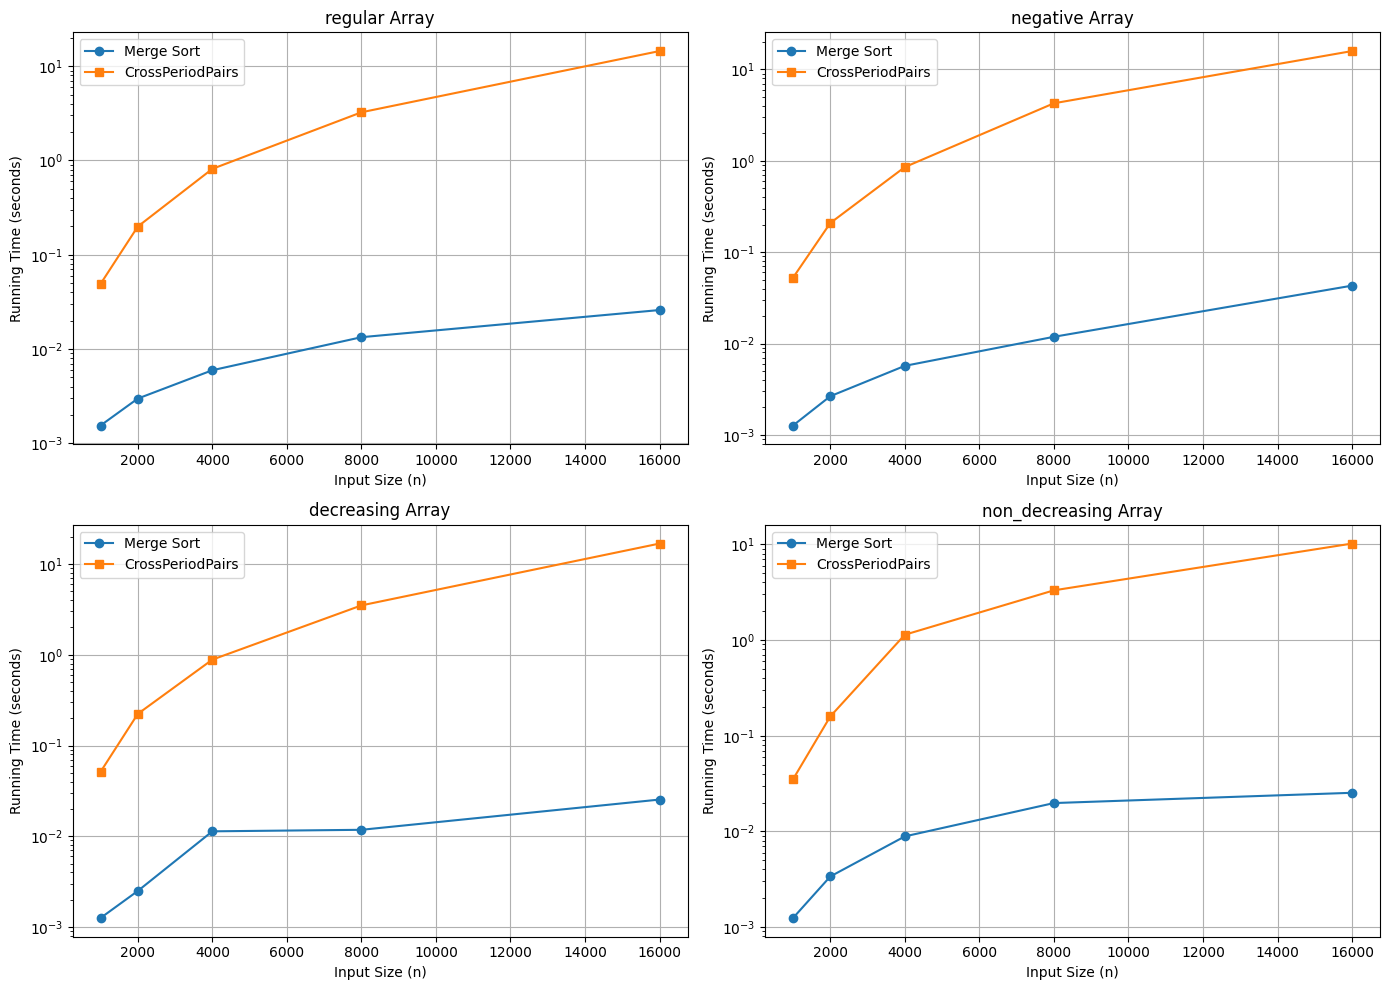

In [27]:
array_types = list(generators.keys())

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, name in zip(axes.flatten(), array_types):
    ms_times = [results[(name, n)]["ms_time"] for n in sizes]

    cross_times = [results[(name, n)]["cross_time"] for n in sizes]

    ax.plot(sizes, ms_times, marker="o", label="Merge Sort")
    ax.plot(sizes, cross_times, marker="s", label="CrossPeriodPairs")

    ax.set_title(f"{name} Array")
    ax.set_xlabel("Input Size (n)")
    ax.set_yscale("log", base=10)
    ax.set_ylabel("Running Time (seconds)")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()


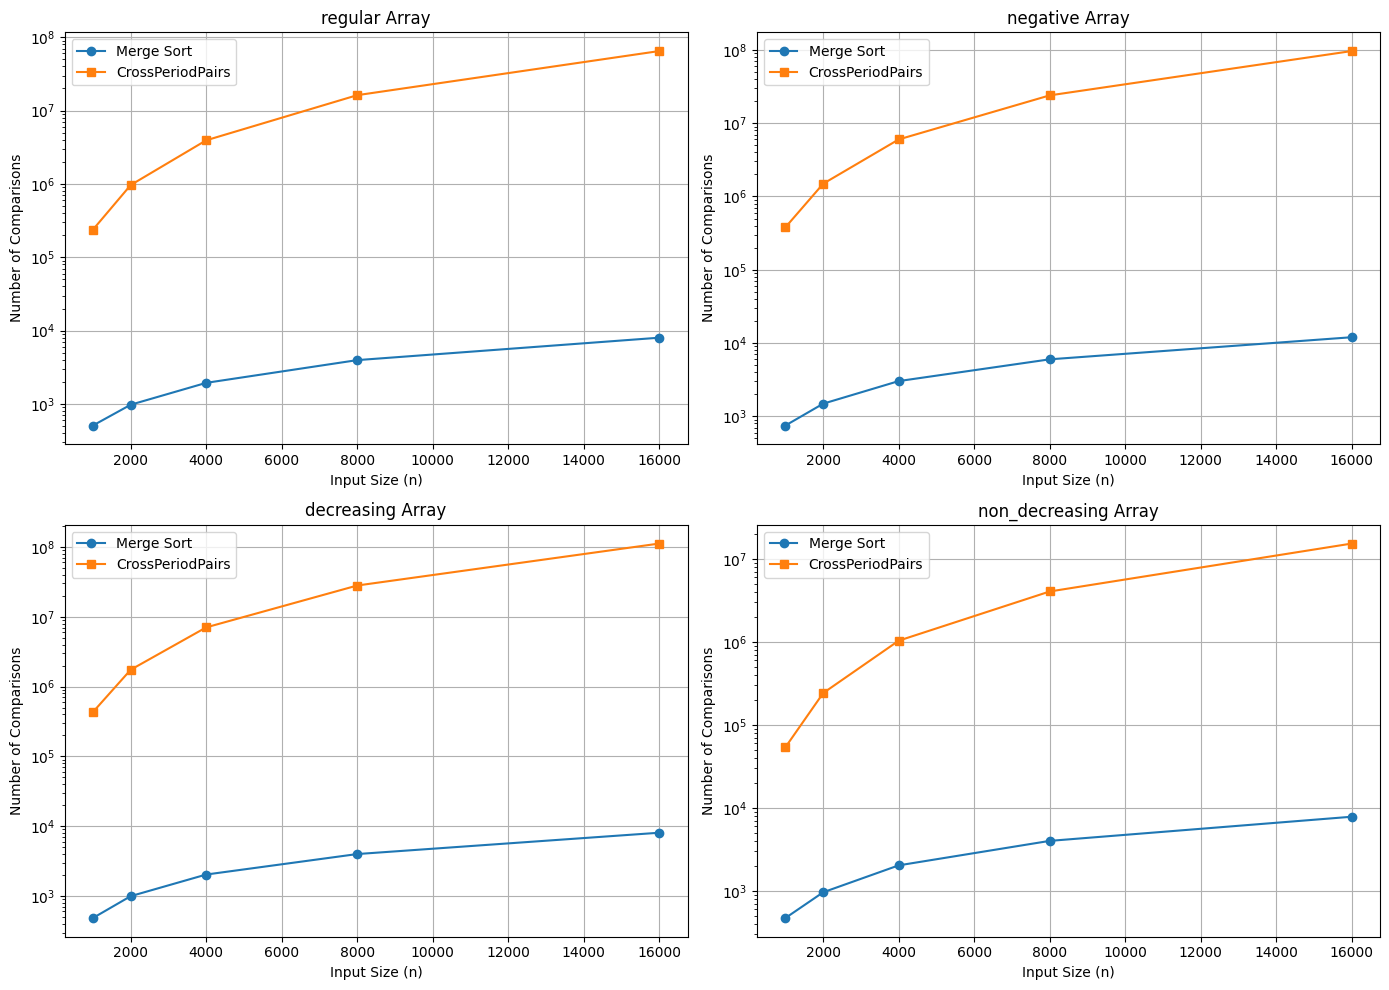

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, name in zip(axes.flatten(), array_types):
    ms_comparisons = [results[(name, n)]["ms_comparisons"] for n in sizes]

    cross_comparisons = [results[(name, n)]["cross_pairs"] for n in sizes]

    ax.plot(sizes, ms_comparisons, marker="o", label="Merge Sort")
    ax.plot(sizes, cross_comparisons, marker="s", label="CrossPeriodPairs")

    ax.set_title(f"{name} Array")
    ax.set_xlabel("Input Size (n)")
    ax.set_yscale("log", base=10)
    ax.set_ylabel("Number of Comparisons")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()
